Customer Churn Prediction Using Machine Learning

In [1]:
# Cell 1: Import required libraries

import os
import requests
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from io import BytesIO
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

print("All required libraries imported successfully!")

All required libraries imported successfully!


In [2]:
# Cell 2: Download and verify the dataset

import requests
import pandas as pd
from io import BytesIO

url = (
    "https://raw.githubusercontent.com/"
    "IBM/telco-customer-churn-on-icp4d/"
    "master/data/Telco-Customer-Churn.csv"
)

response = requests.get(url, timeout=30)

# Stop if the download fails
response.raise_for_status()

# Load the downloaded CSV into a DataFrame
df = pd.read_csv(BytesIO(response.content))

# Verify the dataset structure
assert df.shape == (7043, 21), (
    f"Unexpected dataset shape: {df.shape}"
)

assert "Churn" in df.columns, "Churn column is missing"
assert "customerID" in df.columns, "Customer ID column is missing"

# Save a local copy
df.to_csv("telco_churn.csv", index=False)

print("Dataset downloaded and verified successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())

Dataset downloaded and verified successfully!
Number of rows: 7043
Number of columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Cell 3: Inspect the dataset

print("Dataset dimensions:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Dataset dimensions: (7043, 21)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non

In [4]:
# Cell 4: Check for missing values

print("Missing values in each column:\n")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Missing values in each column:

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Total missing values: 0

Duplicate rows: 0


In [5]:
# Cell 5: Clean TotalCharges

# Convert blank strings into proper missing values
df["TotalCharges"] = df["TotalCharges"].replace(
    r"^\s*$", np.nan, regex=True
)

# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print("TotalCharges data type:", df["TotalCharges"].dtype)
print("Missing TotalCharges values:", df["TotalCharges"].isnull().sum())

display(df[df["TotalCharges"].isnull()])

TotalCharges data type: float64
Missing TotalCharges values: 11


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [6]:
# Cell 6: Verify and handle missing TotalCharges

missing_mask = df["TotalCharges"].isnull()

print(
    "Missing-charge records with zero tenure:",
    (df.loc[missing_mask, "tenure"] == 0).sum()
)

assert (df.loc[missing_mask, "tenure"] == 0).all(), (
    "Review missing TotalCharges values before filling them."
)

df.loc[missing_mask, "TotalCharges"] = 0

print("\nMissing values after cleaning:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nRemaining missing values:", df.isnull().sum().sum())

Missing-charge records with zero tenure: 11

Missing values after cleaning:
Series([], dtype: int64)

Remaining missing values: 0


In [9]:

# Cell 7: Final data quality checks

print("Dataset shape:", df.shape)

print("\nMissing values remaining:", df.isnull().sum().sum())

print("Duplicate rows:", df.duplicated().sum())

print("\nChurn values:")
print(df["Churn"].value_counts())

print("\nChurn values including missing entries:")
print(df["Churn"].value_counts(dropna=False))

# Verify important conditions
assert df.shape == (7043, 21), "Dataset shape is incorrect"
assert df.isnull().sum().sum() == 0, "Missing values remain"
assert set(df["Churn"].unique()) == {"Yes", "No"}, "Unexpected churn labels"

print("\nData quality checks completed successfully!")

Dataset shape: (7043, 21)

Missing values remaining: 0
Duplicate rows: 0

Churn values:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn values including missing entries:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Data quality checks completed successfully!


Customer churn counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Customer churn percentages:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


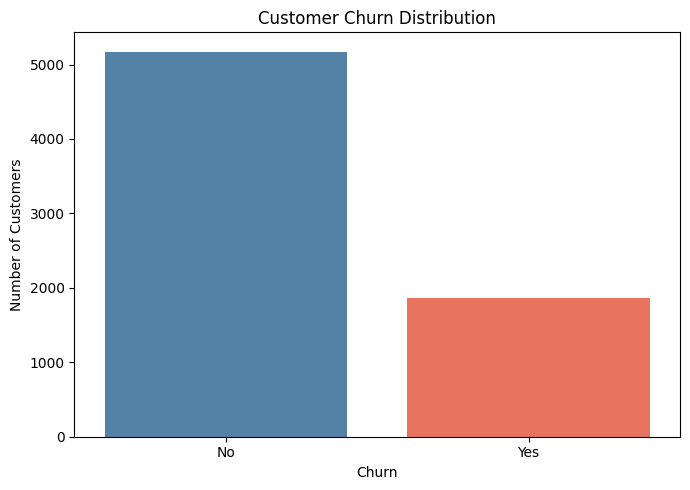

In [10]:

# Cell 8: Analyze the target variable

churn_counts = df["Churn"].value_counts()
churn_percentages = df["Churn"].value_counts(normalize=True) * 100

print("Customer churn counts:")
print(churn_counts)

print("\nCustomer churn percentages:")
print(churn_percentages.round(2))

# Visualize customer churn distribution
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Churn",
    hue="Churn",
    order=["No", "Yes"],
    palette={"No": "steelblue", "Yes": "tomato"},
    legend=False
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

Churn percentage by contract type:
Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


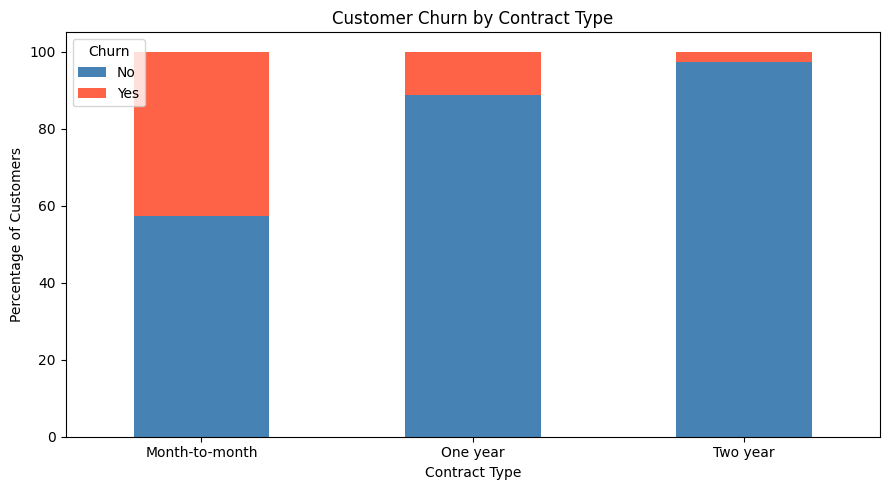

In [11]:

# Cell 9: Churn rate by contract type

contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn percentage by contract type:")
print(contract_churn.round(2))

# Plot churn rates
contract_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    color=["steelblue", "tomato"]
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage of Customers")
plt.legend(title="Churn")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

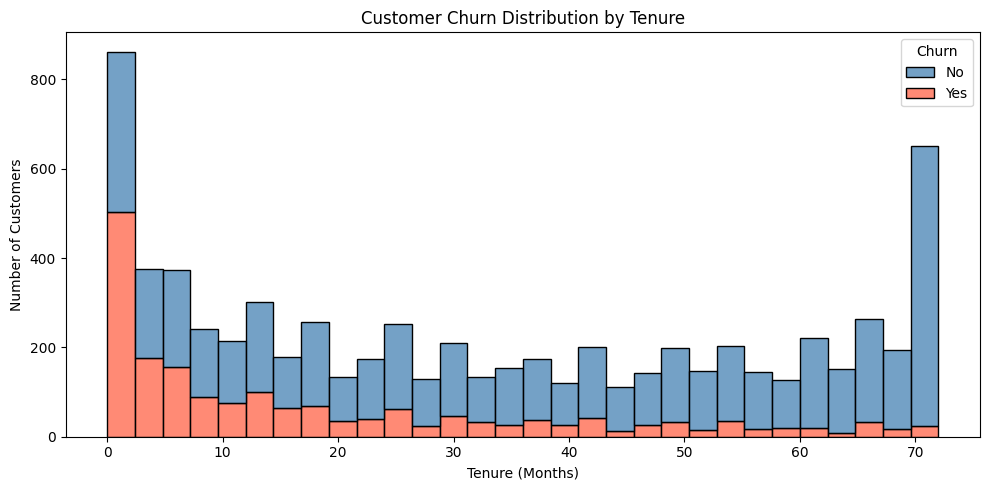

In [12]:

# Cell 10: Analyze churn by customer tenure

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    bins=30,
    multiple="stack",
    palette={"No": "steelblue", "Yes": "tomato"}
)

plt.title("Customer Churn Distribution by Tenure")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

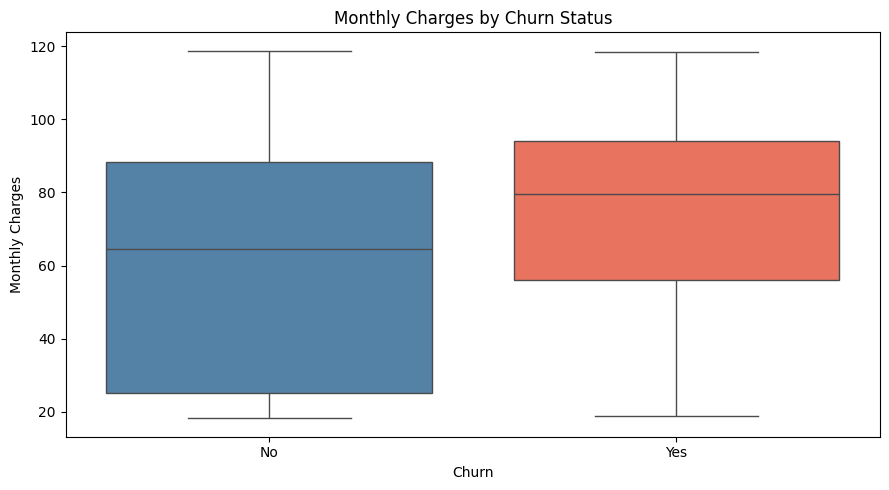


Average monthly charges by churn status:
Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64


In [13]:

# Cell 11: Analyze monthly charges by churn status

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges",
    hue="Churn",
    order=["No", "Yes"],
    palette={"No": "steelblue", "Yes": "tomato"},
    legend=False
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()

print("\nAverage monthly charges by churn status:")
print(df.groupby("Churn")["MonthlyCharges"].mean().round(2))


In [14]:

# Cell 12: Separate features (X) and target (y)

X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"].map({"No": 0, "Yes": 1})

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

print("\nTarget encoding:")
print(y.value_counts().rename(index={0: "No Churn", 1: "Churn"}))

assert y.notnull().all(), "Target contains missing values"

print("\nFeatures and target prepared successfully!")

Feature matrix shape: (7043, 19)
Target vector shape: (7043,)

Target encoding:
Churn
No Churn    5174
Churn       1869
Name: count, dtype: int64

Features and target prepared successfully!


In [15]:

# Cell 13: Identify numerical and categorical features

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

print("\nNumber of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))


Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Number of numerical features: 4
Number of categorical features: 15


In [16]:

# Cell 14: Split data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

print("\nTrain-test split completed successfully!")


Training features: (5634, 19)
Testing features: (1409, 19)

Training target distribution:
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64

Testing target distribution:
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64

Train-test split completed successfully!


In [17]:

# Cell 15: Create preprocessing pipelines

# Process numerical features
numerical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Process categorical features
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")
print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))


Preprocessing pipeline created successfully!
Numerical features: 4
Categorical features: 15


In [18]:

# Cell 16: Train Logistic Regression

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ))
    ]
)

logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")


Logistic Regression trained successfully!


In [19]:

# Cell 17: Evaluate Logistic Regression

y_pred_log = logistic_model.predict(X_test)
y_prob_log = logistic_model.predict_proba(X_test)[:, 1]

logistic_results = {
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_test, y_pred_log),
    "Precision": precision_score(y_test, y_pred_log, zero_division=0),
    "Recall": recall_score(y_test, y_pred_log, zero_division=0),
    "F1-Score": f1_score(y_test, y_pred_log, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob_log)
}

print("Logistic Regression Results:\n")

for metric, value in logistic_results.items():
    if metric != "Model":
        print(f"{metric}: {value:.4f}")

print("\nClassification Report:\n")
print(classification_report(
    y_test,
    y_pred_log,
    target_names=["No Churn", "Churn"],
    zero_division=0
))


Logistic Regression Results:

Accuracy: 0.7381
Precision: 0.5043
Recall: 0.7834
F1-Score: 0.6136
ROC-AUC: 0.8416

Classification Report:

              precision    recall  f1-score   support

    No Churn       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



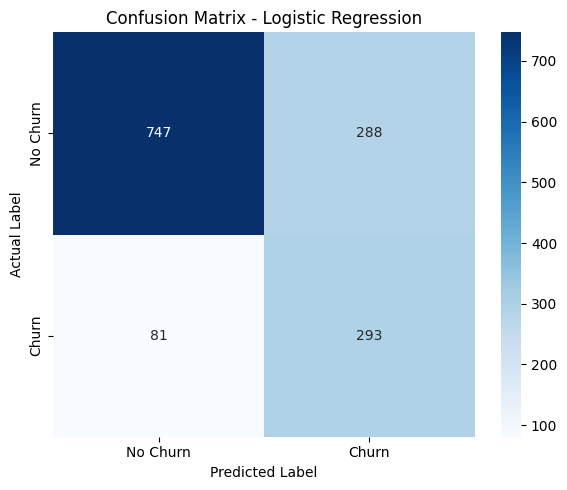

In [20]:

# Cell 18: Confusion matrix for Logistic Regression

cm_log = confusion_matrix(y_test, y_pred_log)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_log,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

In [21]:

# Cell 19: Train Random Forest

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            max_depth=None,
            min_samples_split=2,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

random_forest_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

# Generate predictions
y_pred_rf = random_forest_model.predict(X_test)
y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

print("\nRandom Forest model is ready for evaluation.")

Random Forest trained successfully!

Random Forest model is ready for evaluation.


In [22]:

# Cell 20: Evaluate Random Forest

rf_results = {
    "Model": "Random Forest",
    "Accuracy": accuracy_score(y_test, y_pred_rf),
    "Precision": precision_score(
        y_test, y_pred_rf, zero_division=0
    ),
    "Recall": recall_score(
        y_test, y_pred_rf, zero_division=0
    ),
    "F1-Score": f1_score(
        y_test, y_pred_rf, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_test, y_prob_rf)
}

print("Random Forest Results:\n")

for metric, value in rf_results.items():
    if metric != "Model":
        print(f"{metric}: {value:.4f}")

print("\nClassification Report:\n")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["No Churn", "Churn"],
    zero_division=0
))


Random Forest Results:

Accuracy: 0.7828
Precision: 0.6189
Recall: 0.4733
F1-Score: 0.5364
ROC-AUC: 0.8232

Classification Report:

              precision    recall  f1-score   support

    No Churn       0.82      0.89      0.86      1035
       Churn       0.62      0.47      0.54       374

    accuracy                           0.78      1409
   macro avg       0.72      0.68      0.70      1409
weighted avg       0.77      0.78      0.77      1409



In [23]:

# Cell 21: Install and import XGBoost

%pip install -q xgboost

from xgboost import XGBClassifier

print("XGBoost imported successfully!")


XGBoost imported successfully!


In [24]:

# Cell 22: Train XGBoost

# Calculate the ratio of non-churn to churn customers
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_weight = negative_count / positive_count

xgboost_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", XGBClassifier(
            n_estimators=300,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            scale_pos_weight=scale_weight,
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

xgboost_model.fit(X_train, y_train)

print("XGBoost trained successfully!")

# Generate predictions
y_pred_xgb = xgboost_model.predict(X_test)
y_prob_xgb = xgboost_model.predict_proba(X_test)[:, 1]


XGBoost trained successfully!


In [25]:

# Cell 23: Evaluate XGBoost

xgb_results = {
    "Model": "XGBoost",
    "Accuracy": accuracy_score(y_test, y_pred_xgb),
    "Precision": precision_score(
        y_test, y_pred_xgb, zero_division=0
    ),
    "Recall": recall_score(
        y_test, y_pred_xgb, zero_division=0
    ),
    "F1-Score": f1_score(
        y_test, y_pred_xgb, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_test, y_prob_xgb)
}

print("XGBoost Results:\n")

for metric, value in xgb_results.items():
    if metric != "Model":
        print(f"{metric}: {value:.4f}")

print("\nClassification Report:\n")
print(classification_report(
    y_test,
    y_pred_xgb,
    target_names=["No Churn", "Churn"],
    zero_division=0
))


XGBoost Results:

Accuracy: 0.7601
Precision: 0.5330
Recall: 0.7781
F1-Score: 0.6326
ROC-AUC: 0.8404

Classification Report:

              precision    recall  f1-score   support

    No Churn       0.90      0.75      0.82      1035
       Churn       0.53      0.78      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.76      0.77      1409



In [26]:

# Cell 24: Compare all classification models

results_df = pd.DataFrame([
    logistic_results,
    rf_results,
    xgb_results
])

results_df = results_df.set_index("Model")

print("MODEL COMPARISON")
display(results_df.round(4))

print("\nBest model by ROC-AUC:")
print(results_df["ROC-AUC"].idxmax())

print("\nBest model by recall:")
print(results_df["Recall"].idxmax())

print("\nBest model by accuracy:")
print(results_df["Accuracy"].idxmax())


MODEL COMPARISON


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.7381,0.5043,0.7834,0.6136,0.8416
Random Forest,0.7828,0.6189,0.4733,0.5364,0.8232
XGBoost,0.7601,0.5330,0.7781,0.6326,0.8404



Best model by ROC-AUC:
Logistic Regression

Best model by recall:
Logistic Regression

Best model by accuracy:
Random Forest


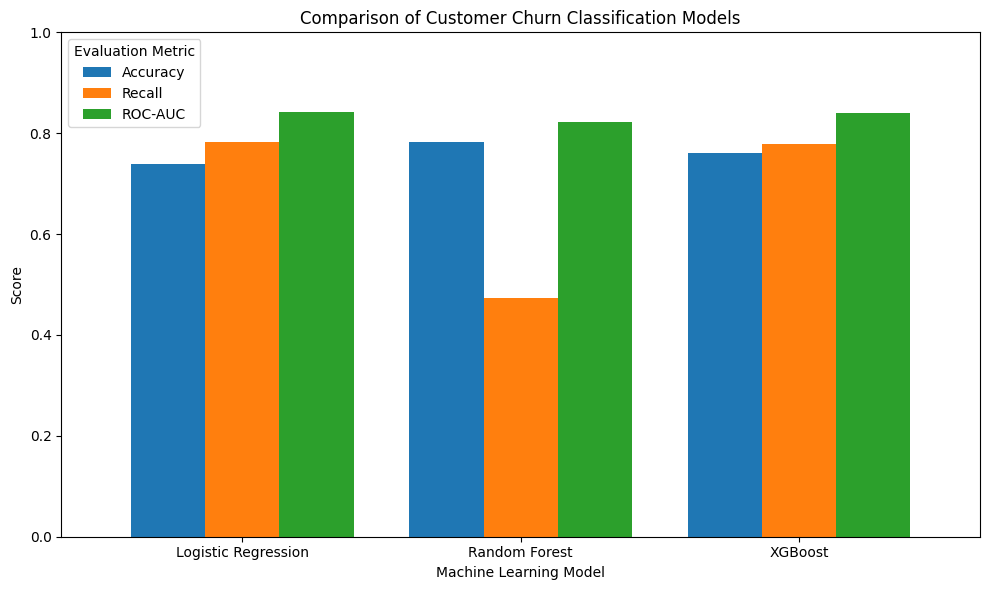

In [27]:

# Cell 25: Compare accuracy, recall and ROC-AUC

metrics_to_plot = ["Accuracy", "Recall", "ROC-AUC"]

results_df[metrics_to_plot].plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1),
    width=0.8
)

plt.title("Comparison of Customer Churn Classification Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(title="Evaluation Metric")
plt.tight_layout()
plt.show()


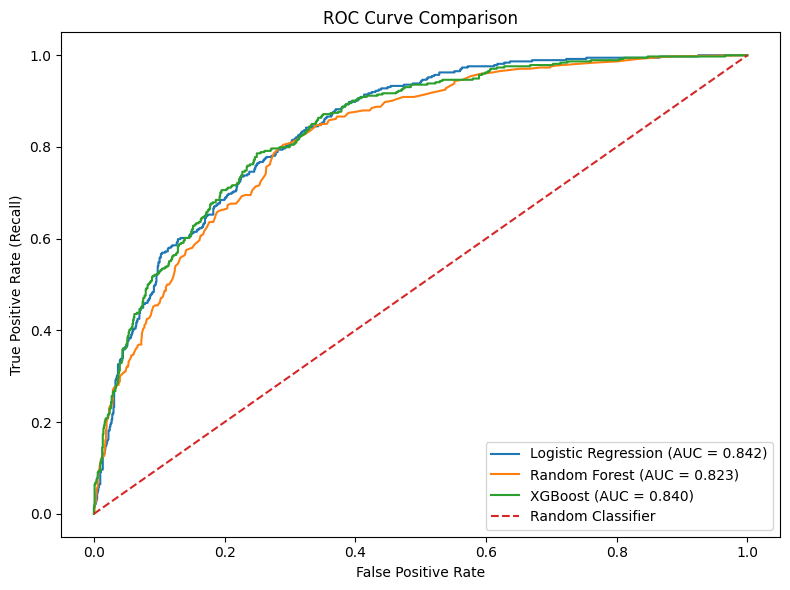

In [28]:

# Cell 26: ROC curve comparison

model_probabilities = {
    "Logistic Regression": y_prob_log,
    "Random Forest": y_prob_rf,
    "XGBoost": y_prob_xgb
}

plt.figure(figsize=(8, 6))

for model_name, probabilities in model_probabilities.items():
    fpr, tpr, thresholds = roc_curve(
        y_test, probabilities
    )

    auc_value = roc_auc_score(y_test, probabilities)

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {auc_value:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


In [29]:
# Cell 27: Extract Random Forest feature importance

# Get the fitted preprocessing step
fitted_preprocessor = random_forest_model.named_steps["preprocessor"]

# Get the fitted Random Forest classifier
fitted_rf = random_forest_model.named_steps["classifier"]

# Get feature names after preprocessing
feature_names = fitted_preprocessor.get_feature_names_out()

# Extract feature importance scores
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": fitted_rf.feature_importances_
})

# Make feature names easier to read
importance_df["Feature"] = (
    importance_df["Feature"]
    .str.replace("num__", "", regex=False)
    .str.replace("cat__", "", regex=False)
)

# Sort features by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("Top 15 Important Features:")
display(importance_df.head(15))


Top 15 Important Features:


,Feature,Importance
3,TotalCharges,0.140630
1,tenure,0.132414
2,MonthlyCharges,0.122886
36,Contract_Month-to-month,0.069253
18,OnlineSecurity_No,0.039429
38,Contract_Two year,0.035437
27,TechSupport_No,0.033811
43,PaymentMethod_Electronic check,0.028715
16,InternetService_Fiber optic,0.028029
21,OnlineBackup_No,0.017476


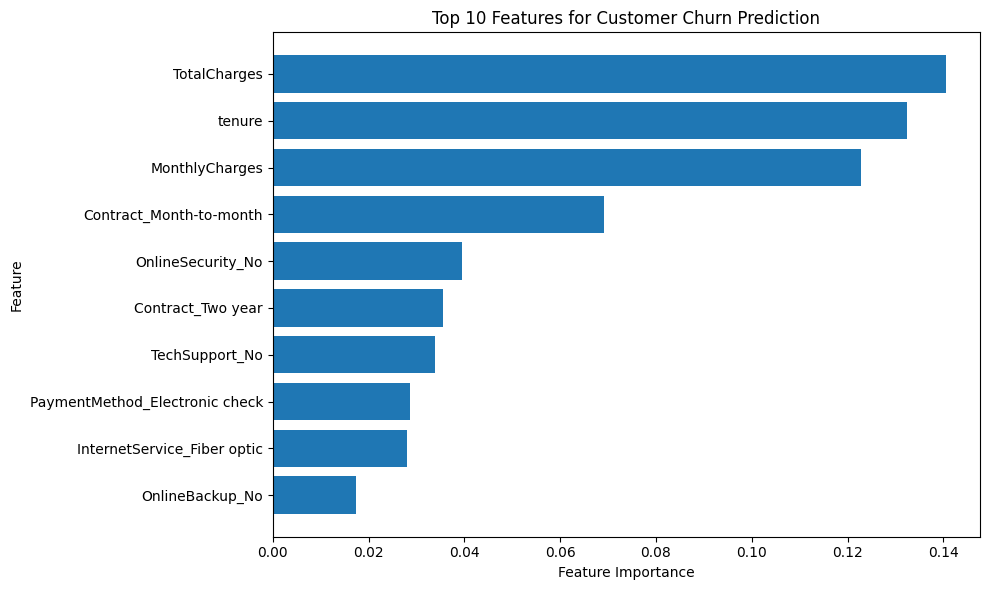

In [30]:
# Cell 28: Plot the top 10 important features

top_features = importance_df.head(10).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 10 Features for Customer Churn Prediction")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [31]:
# Cell 29: Final evaluation summary

print("=" * 55)
print("CUSTOMER CHURN PREDICTION - MODEL SUMMARY")
print("=" * 55)

display(results_df.round(4))

best_recall_model = results_df["Recall"].idxmax()
best_auc_model = results_df["ROC-AUC"].idxmax()
best_accuracy_model = results_df["Accuracy"].idxmax()

print("\nKey Findings:")
print(f"Best model by recall: {best_recall_model}")
print(f"Best model by ROC-AUC: {best_auc_model}")
print(f"Best model by accuracy: {best_accuracy_model}")

print("\nDataset summary:")
print(f"Total customers: {len(df)}")
print(f"Customers who churned: {(df['Churn'] == 'Yes').sum()}")
print(
    "Churn rate: "
    f"{(df['Churn'] == 'Yes').mean() * 100:.2f}%"
)

print("\nTop 5 important features:")
print(importance_df.head(5)["Feature"].to_list())


CUSTOMER CHURN PREDICTION - MODEL SUMMARY


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.7381,0.5043,0.7834,0.6136,0.8416
Random Forest,0.7828,0.6189,0.4733,0.5364,0.8232
XGBoost,0.7601,0.5330,0.7781,0.6326,0.8404



Key Findings:
Best model by recall: Logistic Regression
Best model by ROC-AUC: Logistic Regression
Best model by accuracy: Random Forest

Dataset summary:
Total customers: 7043
Customers who churned: 1869
Churn rate: 26.54%

Top 5 important features:
['TotalCharges', 'tenure', 'MonthlyCharges', 'Contract_Month-to-month', 'OnlineSecurity_No']


In [32]:

# Cell 30: Save the trained XGBoost pipeline

import joblib
import os

os.makedirs("models", exist_ok=True)

model_path = "models/xgboost_churn_pipeline.joblib"

joblib.dump(xgboost_model, model_path)

print("Model saved successfully!")
print("Saved location:", model_path)
print("File size:", round(os.path.getsize(model_path) / 1024, 2), "KB")


Model saved successfully!
Saved location: models/xgboost_churn_pipeline.joblib
File size: 484.98 KB


In [33]:

# Cell 31: Load the model and verify predictions

loaded_model = joblib.load(
    "models/xgboost_churn_pipeline.joblib"
)

# Predict using a small sample from the test set
sample_customers = X_test.iloc[:5]

sample_predictions = loaded_model.predict(sample_customers)
sample_probabilities = loaded_model.predict_proba(
    sample_customers
)[:, 1]

verification_df = pd.DataFrame({
    "Actual Churn": y_test.iloc[:5].map({
        0: "No",
        1: "Yes"
    }).values,
    "Predicted Churn": np.where(
        sample_predictions == 1, "Yes", "No"
    ),
    "Churn Probability": sample_probabilities.round(3)
}, index=sample_customers.index)

display(verification_df)

print("Saved model loaded and tested successfully!")


,Actual Churn,Predicted Churn,Churn Probability
437,No,No,0.016
2280,No,Yes,0.938
2235,No,No,0.183
4460,No,No,0.475
3761,No,No,0.014


Saved model loaded and tested successfully!


In [34]:
# Cell 32: Export project results

os.makedirs("results", exist_ok=True)

results_df.to_csv(
    "results/model_comparison.csv"
)

importance_df.to_csv(
    "results/feature_importance.csv",
    index=False
)

print("Project results exported successfully!")

print("\nFiles created:")
print("- results/model_comparison.csv")
print("- results/feature_importance.csv")


Project results exported successfully!

Files created:
- results/model_comparison.csv
- results/feature_importance.csv


In [38]:
# Cell 34: Create README.md

# Calculate churn rate directly
churn_rate = (df["Churn"] == "Yes").mean() * 100

readme_content = f"""
# Telecom Customer Churn Prediction

## Project Overview
This machine learning project predicts whether telecom customers
are likely to leave a service using customer account, service,
contract, tenure, and billing information.

## Objectives
- Analyze customer churn patterns using exploratory data analysis.
- Train classification models to predict customer churn.
- Compare models using accuracy, precision, recall, F1-score,
  and ROC-AUC.
- Identify important features related to model predictions.

## Dataset
The project uses the IBM Telco Customer Churn dataset.
It contains {len(df)} customer records and {df.shape[1]} columns.

The observed churn rate is {churn_rate:.2f}%.

## Methodology
1. Load and inspect the dataset.
2. Clean the TotalCharges column.
3. Explore churn distribution, contract type, tenure, and charges.
4. Split the data into training and testing sets.
5. Preprocess numerical and categorical features using a pipeline.
6. Train Logistic Regression, Random Forest, and XGBoost models.
7. Evaluate and compare the models.
8. Examine Random Forest feature importance.

## Model Evaluation
The models were evaluated on the same test set.

{results_df.round(4).to_string()}

Best model by recall: {results_df["Recall"].idxmax()}

Best model by ROC-AUC: {results_df["ROC-AUC"].idxmax()}

Best model by accuracy: {results_df["Accuracy"].idxmax()}

## Key Findings
The comparison highlights the trade-offs between identifying
customers who churn and making accurate predictions overall.
Feature importance can help identify characteristics useful
for further customer retention analysis.

Refer to the notebook and exported results for detailed findings
and visualizations.

## Technologies Used
- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- XGBoost
- Google Colab

## Limitations
Predictions are not guaranteed to be correct.
Feature importance indicates predictive usefulness, not causation.
The model should be validated on suitable data before deployment.

## Internship Project
Prepared as part of the Customer Churn Prediction project
for the CodeTech internship.
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme_content.strip() + "\n")

print("README.md created successfully!")


README.md created successfully!


In [39]:

# Cell 35: Verify project files

from pathlib import Path

project_files = [
    Path("telco_churn.csv"),
    Path("README.md"),
    Path("models/xgboost_churn_pipeline.joblib"),
    Path("results/model_comparison.csv"),
    Path("results/feature_importance.csv")
]

print("PROJECT FILE INVENTORY")
print("-" * 45)

for file_path in project_files:
    if file_path.exists():
        size_kb = file_path.stat().st_size / 1024
        print(f"FOUND: {file_path} ({size_kb:.2f} KB)")
    else:
        print(f"MISSING: {file_path}")

print("\nInventory check completed.")


PROJECT FILE INVENTORY
---------------------------------------------
FOUND: telco_churn.csv (948.48 KB)
FOUND: README.md (2.30 KB)
FOUND: models/xgboost_churn_pipeline.joblib (484.98 KB)
FOUND: results/model_comparison.csv (0.36 KB)
FOUND: results/feature_importance.csv (1.85 KB)

Inventory check completed.


In [40]:

# Cell 36: Package project files into a ZIP archive

import shutil
from pathlib import Path

files_to_package = [
    "telco_churn.csv",
    "README.md",
    "models/xgboost_churn_pipeline.joblib",
    "results/model_comparison.csv",
    "results/feature_importance.csv"
]

missing_files = [
    file for file in files_to_package
    if not Path(file).exists()
]

if missing_files:
    raise FileNotFoundError(
        f"These files are missing: {missing_files}"
    )

zip_path = shutil.make_archive(
    "customer_churn_project",
    "zip",
    root_dir=".",
    base_dir="README.md"
)

# Create a clean project folder for the archive
import zipfile

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zip_file:
    for file in files_to_package:
        zip_file.write(file, arcname=file)

print("Project archive created:", zip_path)


Project archive created: /content/customer_churn_project.zip


In [41]:
# Cell 37: Download project archive

from google.colab import files

files.download("customer_churn_project.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>